In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


In [18]:
data_train_path = 'train'
data_test_path =  'test'
data_val_path = 'validation'

In [19]:
img_width = 180
img_height = 180

In [20]:
data_train = tf.keras.utils.image_dataset_from_directory(
    data_train_path,
    shuffle=True,
    image_size=(img_width, img_height),
    batch_size=32,
    validation_split=False
)

Found 3115 files belonging to 36 classes.


In [21]:
data_cat = data_train.class_names

In [41]:
data_cat

['apple',
 'banana',
 'beetroot',
 'bell pepper',
 'cabbage',
 'capsicum',
 'carrot',
 'cauliflower',
 'chilli pepper',
 'corn',
 'cucumber',
 'eggplant',
 'garlic',
 'ginger',
 'grapes',
 'jalepeno',
 'kiwi',
 'lemon',
 'lettuce',
 'mango',
 'onion',
 'orange',
 'paprika',
 'pear',
 'peas',
 'pineapple',
 'pomegranate',
 'potato',
 'raddish',
 'soy beans',
 'spinach',
 'sweetcorn',
 'sweetpotato',
 'tomato',
 'turnip',
 'watermelon']

In [22]:
data_val = tf.keras.utils.image_dataset_from_directory(
    data_val_path,
    image_size = (img_height, img_width),
    batch_size = 32,
    shuffle = False,
    validation_split = False
)

Found 351 files belonging to 36 classes.


In [23]:
data_test = tf.keras.utils.image_dataset_from_directory(
    data_test_path,
    image_size = (img_height, img_width),
    batch_size = 32,
    shuffle = False,
    validation_split = False
)

Found 359 files belonging to 36 classes.


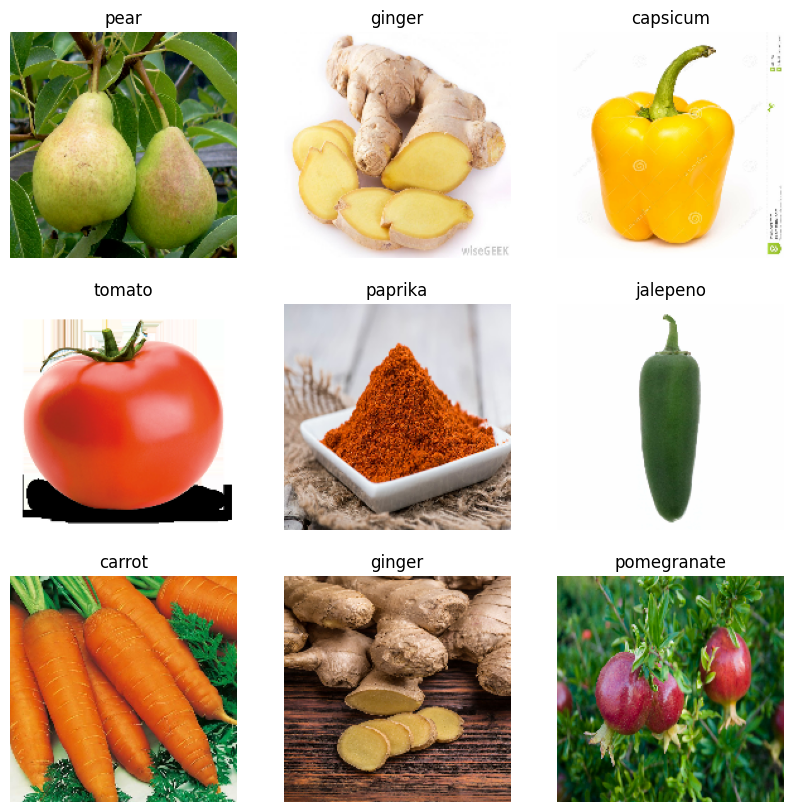

In [24]:
plt.figure(figsize=(10,10))
for image, labels in data_train.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype('uint8'))
        plt.title(data_cat[labels[i]])
        plt.axis('off')

In [25]:
from tensorflow.keras.models import Sequential

In [26]:
model = Sequential([
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(len(data_cat))
])

In [29]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

In [31]:
epochs_size = 25
history = model.fit(data_train, validation_data=data_val, epochs=epochs_size)

Epoch 1/25


98/98 ━━━━━━━━━━━━━━━━━━━━ 75s 744ms/step - accuracy: 0.0717 - loss: 3.4169 - val_accuracy: 0.4274 - val_loss: 2.1416
Epoch 2/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 48s 489ms/step - accuracy: 0.3266 - loss: 2.3343 - val_accuracy: 0.6068 - val_loss: 1.5252
Epoch 3/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 52s 528ms/step - accuracy: 0.4797 - loss: 1.8032 - val_accuracy: 0.7692 - val_loss: 1.0029
Epoch 4/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 55s 562ms/step - accuracy: 0.6304 - loss: 1.2924 - val_accuracy: 0.8832 - val_loss: 0.6038
Epoch 5/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 56s 572ms/step - accuracy: 0.7695 - loss: 0.8164 - val_accuracy: 0.8889 - val_loss: 0.5266
Epoch 6/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 49s 496ms/step - accuracy: 0.8662 - loss: 0.4831 - val_accuracy: 0.9145 - val_loss: 0.5243
Epoch 7/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 50s 510ms/step - accuracy: 0.9123 - loss: 0.2988 - val_accuracy: 0.9288 - val_loss: 0.4285
Epoch 8/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 51s 514ms/step - accuracy: 0.9493 - loss: 0.1899 - val_accuracy: 0.954

Text(0.5, 1.0, 'Loss')

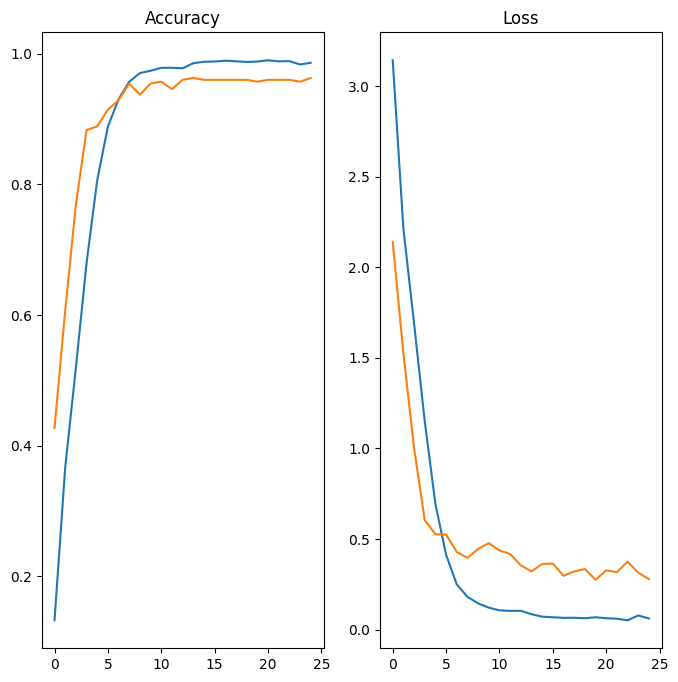

In [34]:
epocs_range = range(epochs_size)
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(epocs_range, hostory.history['accuracy'], label = 'Traing Accuracy')
plt.plot(epocs_range, hostory.history['val_accuracy'], label = 'Validation Accuracy')
plt.title('Accuracy')


plt.subplot(1,2,2)
plt.plot(epocs_range, hostory.history['loss'], label = 'Traing Loss')
plt.plot(epocs_range, hostory.history['val_loss'], label = 'Validation Loss')
plt.title('Loss')

In [50]:
image = 'image.jpg'
image = tf.keras.utils.load_img(image, target_size=(img_height, img_width))
img_arr = tf.keras.utils.array_to_img(image)
img_batch = tf.expand_dims(img_arr, 0)

In [51]:
predict = model.predict(img_batch)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


In [53]:
score = tf.nn.softmax(predict)
print('Image is {} Predicted with accuracy of {:0.2f} %'.format(data_cat[np.argmax(score)], np.max(score)*100))

Image is chilli pepper Predicted with accuracy of 99.80 %


In [40]:
model.save('Image_Classification.keras')